<div align="center">
<h1 > Riyadh Cardiorespiratory Hospital Admissions Dataset (2020–2024) </h1>
<img src="MOH-1.png" alt="Dataset Preview" width="600">
</div>

## 1 ) Data Understanding : 

| Column Name | Description |
| :--- | :--- |
| **admission_date** |The precise date and time of hospital admission (YYYY-MM-DD HH:mm:ss). |
| **hospital_name** | Name of the hospital where the admission occurred (e.g., Riyadh General Hospital). |
| **admission_count** | The number of admissions during the specified hour. |
| **condition_type** | Type of cardiorespiratory condition (e.g., Asthma, COPD, Heart Attack, Other Respiratory Issues).|
| **patient_age_group** | The age group of admitted patients (e.g., 0–17, 18–45, 46–65, 66+). |
| **patient_gender** | Gender of the patients (Male/Female). |
| **readmission_count** |  Count of patients readmitted within 30 days. |
| **severity_level** | Severity level of the condition upon admission (Mild, Moderate, Severe). |
| **length_of_stay_avg** | Average length of stay (in days) for admitted patients.|
| **seasonal_indicator** | Seasonal classification for the date of admission (Winter, Spring, Summer, Fall).|
| **comorbid_conditions_count** | Number of additional health conditions affecting admitted patients. |
| **primary_diagnosis_code** |Diagnostic code for the primary condition (e.g., J45, J44, I21). |
| **daily_medication_dosage** | Total daily dosage of medications prescribed for cardiorespiratory conditions (mg). |
| **emergency_visit_count** | The number of emergency visits for cardiorespiratory issues during the hour. |


## 2) Data Exploration 

In [1]:
import numpy as np 
import pandas as pd 
import plotly.express as px 
import streamlit as st

In [2]:
df =pd.read_csv(r"C:\Users\Latif\Desktop\Epsilon Data Analysis With Python Project\Hospital_Dataset_2020_2024.csv")
df

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,comorbid_conditions_count,primary_diagnosis_code,daily_medication_dosage,emergency_visit_count
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,1,Other,17.455517,2
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,0,Other,15.099498,3
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,2,I21,23.087843,3
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,3,J45,25.247579,2
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,3,J45,18.255290,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41539,2024-09-26 19:00:00,King Saud Hospital,4,Asthma,46-65,Male,1,Moderate,6.560851,Fall,1,Other,19.060730,1
41540,2024-09-26 20:00:00,Dammam General Hospital,3,COPD,0-17,Male,0,Mild,4.453949,Fall,2,Other,17.128869,1
41541,2024-09-26 21:00:00,Riyadh National Hospital,2,Asthma,46-65,Male,0,Moderate,4.248567,Fall,1,J45,15.250912,1
41542,2024-09-26 22:00:00,King Saud Hospital,0,Asthma,18-45,Male,0,Mild,4.666558,Fall,3,J44,23.296328,0


## 2.1 Cleaning Steps 
#### 2.1.1 Checking Data Types 

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   admission_date             41544 non-null  object 
 1   hospital_name              41544 non-null  object 
 2   admission_count            41544 non-null  int64  
 3   condition_type             41544 non-null  object 
 4   patient_age_group          41544 non-null  object 
 5   patient_gender             41544 non-null  object 
 6   readmission_count          41544 non-null  int64  
 7   severity_level             41544 non-null  object 
 8   length_of_stay_avg         41544 non-null  float64
 9   seasonal_indicator         41544 non-null  object 
 10  comorbid_conditions_count  41544 non-null  int64  
 11  primary_diagnosis_code     41544 non-null  object 
 12  daily_medication_dosage    41544 non-null  float64
 13  emergency_visit_count      41544 non-null  int

In [4]:
df['admission_date']=pd.to_datetime(df['admission_date'])
df['admission_date']

0       2020-01-01 00:00:00
1       2020-01-01 01:00:00
2       2020-01-01 02:00:00
3       2020-01-01 03:00:00
4       2020-01-01 04:00:00
                ...        
41539   2024-09-26 19:00:00
41540   2024-09-26 20:00:00
41541   2024-09-26 21:00:00
41542   2024-09-26 22:00:00
41543   2024-09-26 23:00:00
Name: admission_date, Length: 41544, dtype: datetime64[ns]

#### 2.1.2 Checking Missing Values 

In [5]:
df.isna().sum()

admission_date               0
hospital_name                0
admission_count              0
condition_type               0
patient_age_group            0
patient_gender               0
readmission_count            0
severity_level               0
length_of_stay_avg           0
seasonal_indicator           0
comorbid_conditions_count    0
primary_diagnosis_code       0
daily_medication_dosage      0
emergency_visit_count        0
dtype: int64

In [6]:
df['daily_medication_dosage']=df['daily_medication_dosage'].round(2)
df['daily_medication_dosage']

0        17.46
1        15.10
2        23.09
3        25.25
4        18.26
         ...  
41539    19.06
41540    17.13
41541    15.25
41542    23.30
41543    21.35
Name: daily_medication_dosage, Length: 41544, dtype: float64

#### 2.1.3 Checking Duplicates 

In [7]:
df.duplicated().sum()

np.int64(0)

#### 2.1.4 Checking Outliers 

In [8]:
for col in df.select_dtypes(include='number').columns:
    fig=px.box(df, x= col , color_discrete_sequence=['#49A684'])
    fig.show()

#### 2.1.5 Checking Inconsistent Values

In [9]:
df.describe(include='object')

,hospital_name,condition_type,patient_age_group,patient_gender,severity_level,seasonal_indicator,primary_diagnosis_code
count,41544,41544,41544,41544,41544,41544,41544
unique,8,4,4,2,3,4,4
top,Riyadh National Hospital,Asthma,18-45,Male,Moderate,Spring,J45
freq,5378,20752,16708,24938,16636,11040,16759


In [10]:
df.describe().round(2)

,admission_date,admission_count,readmission_count,length_of_stay_avg,comorbid_conditions_count,daily_medication_dosage,emergency_visit_count
count,41544,41544.00,41544.00,41544.00,41544.00,41544.00,41544.00
mean,2022-05-15 11:30:00,2.00,0.50,4.99,2.00,20.02,1.01
min,2020-01-01 00:00:00,0.00,0.00,1.00,0.00,5.00,0.00
25%,2021-03-08 17:45:00,1.00,0.00,3.96,1.00,16.65,0.00
50%,2022-05-15 11:30:00,2.00,0.00,4.99,2.00,20.03,1.00
75%,2023-07-22 05:15:00,3.00,1.00,6.01,3.00,23.41,2.00
max,2024-09-26 23:00:00,10.00,5.00,10.00,11.00,40.00,7.00
std,NaN,1.42,0.71,1.50,1.42,4.98,1.00


In [11]:
cat_cols=df.select_dtypes(include='object').columns
cat_cols

Index(['hospital_name', 'condition_type', 'patient_age_group',
       'patient_gender', 'severity_level', 'seasonal_indicator',
       'primary_diagnosis_code'],
      dtype='object')

In [12]:
for col in cat_cols:
    print(col)
    print(df[col].nunique())
    print(df[col].unique())
    print('*'*100)

hospital_name
8
['Mecca City Hospital' 'Dammam General Hospital'
 'Medina Specialist Hospital' 'Dammam Central Hospital'
 'King Saud Hospital' 'Jeddah National Hospital'
 'Riyadh National Hospital' 'Riyadh General Hospital']
****************************************************************************************************
condition_type
4
['Asthma' 'COPD' 'Heart Attack' 'Other Respiratory Issues']
****************************************************************************************************
patient_age_group
4
['46-65' '0-17' '18-45' '66+']
****************************************************************************************************
patient_gender
2
['Female' 'Male']
****************************************************************************************************
severity_level
3
['Moderate' 'Mild' 'Severe']
****************************************************************************************************
seasonal_indicator
4
['Winter' 'Spring' 'Summer' 'Fall']
****

## 3.Data Analysis

In [13]:
df.head()

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,comorbid_conditions_count,primary_diagnosis_code,daily_medication_dosage,emergency_visit_count
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,1,Other,17.46,2
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,0,Other,15.10,3
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,2,I21,23.09,3
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,3,J45,25.25,2
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,3,J45,18.26,1


## 3.1 Univariate Analysis

In [14]:
for col in df.columns:
    fig= px.histogram(df,x= col,color_discrete_sequence=['#A69563'],text_auto= True )
    fig.show()

## 3.2 1. Temporal & Seasonal Trend Analysis

### How have total admission counts and emergency visits evolved year-over-year from 2020 through September 2024?

In [15]:
df['Year']=df['admission_date'].dt.year
df['Year']

0        2020
1        2020
2        2020
3        2020
4        2020
         ... 
41539    2024
41540    2024
41541    2024
41542    2024
41543    2024
Name: Year, Length: 41544, dtype: int32

In [16]:
yearly_trend=df.groupby('Year')[['admission_count','emergency_visit_count']].sum().reset_index()
yearly_trend

,Year,admission_count,emergency_visit_count
0,2020,17736,8823
1,2021,17425,8851
2,2022,17592,8901
3,2023,17442,8731
4,2024,12933,6478


In [17]:
fig_pattern=px.line(yearly_trend, x='Year', y=['admission_count','emergency_visit_count'], color_discrete_sequence=['#49A684','#A69563'],markers=True)
fig_pattern.update_layout(xaxis=dict(tickmode='linear', dtick=1))
fig_pattern.show()

In [18]:
df['Month'] = df['admission_date'].dt.month_name()
monthly_pattern = df.groupby('Month')['admission_count'].mean().reset_index().round(2)
monthly_pattern 

,Month,admission_count
0,April,1.94
1,August,2.00
2,December,2.03
3,February,2.00
4,January,1.96
5,July,1.99
6,June,2.03
7,March,2.01
8,May,2.02
9,November,2.01


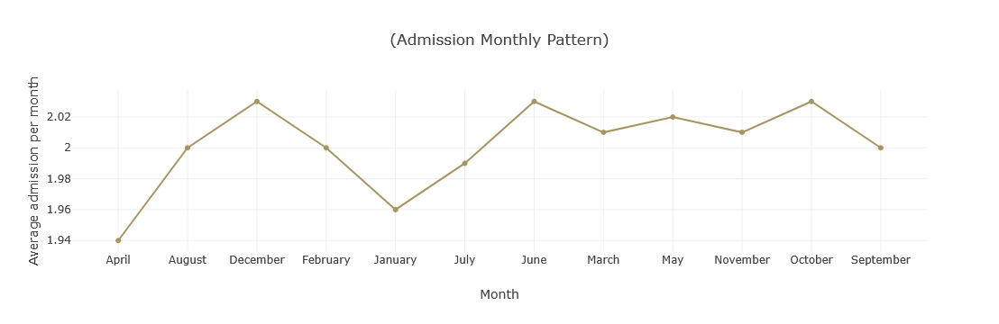

In [19]:
fig_mon = px.line( monthly_pattern, x='Month', y='admission_count', title='(Admission Monthly Pattern)',color_discrete_sequence=['#A69563'],labels={ 'admission_count': 'Average admission per month'},markers=True).update_xaxes(tickmode='linear', tick0=1, dtick=1)
fig_mon.show()

In [20]:
df['Hour'] = df['admission_date'].dt.hour
Hour_pattern = df.groupby('Hour')['admission_count'].mean().reset_index().round(2)
Hour_pattern 

,Hour,admission_count
0,0,2.04
1,1,1.95
2,2,1.99
3,3,2.03
4,4,2.00
5,5,1.98
6,6,1.96
7,7,2.03
8,8,2.01
9,9,2.01


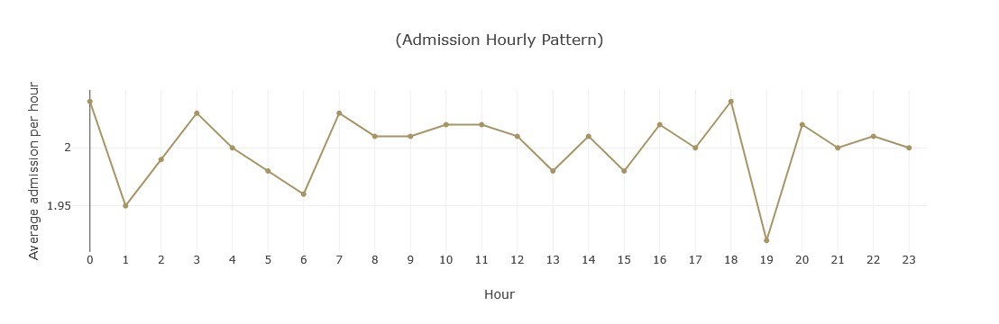

In [21]:
fig_hour = px.line(Hour_pattern , x='Hour', y='admission_count', title='(Admission Hourly Pattern)',color_discrete_sequence=['#A69563'],labels={ 'admission_count': 'Average admission per hour'},markers=True,).update_xaxes(range=[-0.5,23.5],tickmode='linear', tick0=1, dtick=1)
fig_hour.show()

### ** Investigating correlations between environmental factors and hospitalizations for respiratory and cardiovascular conditions

In [22]:
months_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]

In [23]:
monthly_seasonal_df = df.groupby(['Month','seasonal_indicator','condition_type'])['admission_count'].mean().reset_index().round(2)
monthly_seasonal_df["Month"] = pd.Categorical( monthly_seasonal_df["Month"], categories=months_order, ordered=True)
monthly_seasonal_df = monthly_seasonal_df.sort_values("Month")
monthly_seasonal_df

,Month,seasonal_indicator,condition_type,admission_count
19,January,Winter,Other Respiratory Issues,1.97
18,January,Winter,Heart Attack,1.76
17,January,Winter,COPD,2.04
16,January,Winter,Asthma,1.97
15,February,Winter,Other Respiratory Issues,2.07
14,February,Winter,Heart Attack,2.03
13,February,Winter,COPD,2.00
12,February,Winter,Asthma,1.97
28,March,Spring,Asthma,2.04
31,March,Spring,Other Respiratory Issues,1.96


In [24]:
fig_env = px.line( monthly_seasonal_df, x='Month', y='admission_count', color='condition_type',facet_row='seasonal_indicator', title='Respiratory & Cardiovascular Admissions Across Seasons',template='plotly_white',height=1100)
fig_env.update_xaxes(matches=None)
fig_env.update_yaxes(matches=None)
fig_env.show()

### Analysis of Facility & Operational Performance of each hospital

In [25]:
dis_fig=px.pie(df,names='hospital_name',title='Distribution of Admission over Hospitals',template='plotly_white')
dis_fig.show()

In [26]:
hospital_summary = (df.groupby('hospital_name').agg({'admission_count': 'sum','length_of_stay_avg': 'mean','emergency_visit_count': 'sum',}).reset_index().round(2))
hospital_summary

,hospital_name,admission_count,length_of_stay_avg,emergency_visit_count
0,Dammam Central Hospital,10495,4.99,5316
1,Dammam General Hospital,10177,4.98,5172
2,Jeddah National Hospital,10500,5.01,5174
3,King Saud Hospital,10310,4.98,5054
4,Mecca City Hospital,10314,4.98,5227
5,Medina Specialist Hospital,10394,5.00,5271
6,Riyadh General Hospital,10200,5.01,5196
7,Riyadh National Hospital,10738,5.00,5374


In [27]:
fig_hosp = px.bar(hospital_summary,x='hospital_name',y=['admission_count', 'emergency_visit_count'],barmode='group',color_discrete_sequence=['#49A684','#A69563'],title='Total Admissions and Emergency Visits by Hospital',text_auto=True,height=500)
fig_hosp

In [28]:
fig_hosp_len = px.bar(hospital_summary,x='hospital_name',y=['length_of_stay_avg'],barmode='group',color_discrete_sequence=['#038C4C'],title='Average of length of admission days by Hospital',text_auto=True,height=400)
fig_hosp_len

### Analysis of Patient Demographics & Epidemiological Insights

In [29]:
age_df=df.groupby(['patient_age_group','condition_type','patient_gender'])['admission_count'].sum().reset_index()
age_df

,patient_age_group,condition_type,patient_gender,admission_count
0,0-17,Asthma,Female,3423
1,0-17,Asthma,Male,4961
2,0-17,COPD,Female,1362
3,0-17,COPD,Male,2106
4,0-17,Heart Attack,Female,684
5,0-17,Heart Attack,Male,978
6,0-17,Other Respiratory Issues,Female,1389
7,0-17,Other Respiratory Issues,Male,1914
8,18-45,Asthma,Female,6721
9,18-45,Asthma,Male,10065


In [30]:
age_con_fig = px.bar(age_df,x='patient_age_group',y='admission_count',color='condition_type',barmode='group',facet_row='patient_gender',template='plotly_white',height=1000)
age_con_fig.show()


In [31]:
severe_df=df.groupby(['condition_type','severity_level','patient_age_group','patient_gender'])['admission_count'].sum().reset_index()
severe_df

,condition_type,severity_level,patient_age_group,patient_gender,admission_count
0,Asthma,Mild,0-17,Female,1438
1,Asthma,Mild,0-17,Male,1948
2,Asthma,Mild,18-45,Female,2779
3,Asthma,Mild,18-45,Male,4013
4,Asthma,Mild,46-65,Female,1908
...,...,...,...,...,...
91,Other Respiratory Issues,Severe,18-45,Male,841
92,Other Respiratory Issues,Severe,46-65,Female,389
93,Other Respiratory Issues,Severe,46-65,Male,586
94,Other Respiratory Issues,Severe,66+,Female,180


In [32]:
gender_con_fig=px.bar(severe_df,x='patient_age_group',y='admission_count',color='severity_level',facet_col='condition_type',facet_row='patient_gender',barmode='group',template='plotly_white',height=700,width=1500,text_auto=True)
gender_con_fig

### Encoding Ordinal categorical columns:

In [33]:
severity_mapping={'Mild':1,'Moderate':2,'Severe':3}
df['Severity_Encoded']=df['severity_level'].map(severity_mapping)
df['Severity_Encoded']

0        2
1        1
2        2
3        1
4        2
        ..
41539    2
41540    1
41541    2
41542    1
41543    1
Name: Severity_Encoded, Length: 41544, dtype: int64

In [34]:
age_mapping={'0-17':1,'18-45':2,'46-65':3,'66+':4}
df['age_Encoded']=df['patient_age_group'].map(age_mapping)
df['age_Encoded']

0        3
1        1
2        3
3        3
4        2
        ..
41539    3
41540    1
41541    3
41542    2
41543    4
Name: age_Encoded, Length: 41544, dtype: int64

In [35]:
gender_mapping={'Male':0,'Female':2}
df['gender_Encoded']=df['patient_gender'].map(gender_mapping)
df['gender_Encoded']

0        2
1        2
2        2
3        0
4        2
        ..
41539    0
41540    0
41541    0
41542    0
41543    2
Name: gender_Encoded, Length: 41544, dtype: int64

In [36]:
condition_encoded = pd.get_dummies(df['condition_type'], prefix='condition', dtype=int)
condition_encoded

,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,0,1,0,0
...,...,...,...,...
41539,1,0,0,0
41540,0,1,0,0
41541,1,0,0,0
41542,1,0,0,0


In [37]:
df_encoded = pd.concat([df, condition_encoded], axis=1)
df_encoded

,admission_date,hospital_name,admission_count,condition_type,patient_age_group,patient_gender,readmission_count,severity_level,length_of_stay_avg,seasonal_indicator,...,Year,Month,Hour,Severity_Encoded,age_Encoded,gender_Encoded,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
0,2020-01-01 00:00:00,Mecca City Hospital,1,Asthma,46-65,Female,0,Moderate,2.781828,Winter,...,2020,January,0,2,3,2,1,0,0,0
1,2020-01-01 01:00:00,Dammam General Hospital,2,Asthma,0-17,Female,1,Mild,4.141432,Winter,...,2020,January,1,1,1,2,1,0,0,0
2,2020-01-01 02:00:00,Mecca City Hospital,1,Asthma,46-65,Female,1,Moderate,8.507026,Winter,...,2020,January,2,2,3,2,1,0,0,0
3,2020-01-01 03:00:00,Medina Specialist Hospital,3,Asthma,46-65,Male,0,Mild,4.622657,Winter,...,2020,January,3,1,3,0,1,0,0,0
4,2020-01-01 04:00:00,Medina Specialist Hospital,5,COPD,18-45,Female,2,Moderate,5.818385,Winter,...,2020,January,4,2,2,2,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41539,2024-09-26 19:00:00,King Saud Hospital,4,Asthma,46-65,Male,1,Moderate,6.560851,Fall,...,2024,September,19,2,3,0,1,0,0,0
41540,2024-09-26 20:00:00,Dammam General Hospital,3,COPD,0-17,Male,0,Mild,4.453949,Fall,...,2024,September,20,1,1,0,0,1,0,0
41541,2024-09-26 21:00:00,Riyadh National Hospital,2,Asthma,46-65,Male,0,Moderate,4.248567,Fall,...,2024,September,21,2,3,0,1,0,0,0
41542,2024-09-26 22:00:00,King Saud Hospital,0,Asthma,18-45,Male,0,Mild,4.666558,Fall,...,2024,September,22,1,2,0,1,0,0,0


In [38]:
df_encoded_clos= list(df_encoded.select_dtypes(include='number'))
df_encoded_clos

['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Year',
 'Hour',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']

In [39]:
selected_col=['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']
selected_col

['admission_count',
 'readmission_count',
 'length_of_stay_avg',
 'comorbid_conditions_count',
 'daily_medication_dosage',
 'emergency_visit_count',
 'Severity_Encoded',
 'age_Encoded',
 'gender_Encoded',
 'condition_Asthma',
 'condition_COPD',
 'condition_Heart Attack',
 'condition_Other Respiratory Issues']

In [40]:
new_corr_matrix=df_encoded[selected_col].corr()
new_corr_matrix

,admission_count,readmission_count,length_of_stay_avg,comorbid_conditions_count,daily_medication_dosage,emergency_visit_count,Severity_Encoded,age_Encoded,gender_Encoded,condition_Asthma,condition_COPD,condition_Heart Attack,condition_Other Respiratory Issues
admission_count,1.000000,-0.003306,-0.004675,0.002552,0.004654,-0.008431,0.006526,-0.010762,0.002878,-0.000781,0.004905,-0.007576,0.001749
readmission_count,-0.003306,1.000000,-0.002775,0.000090,0.001654,0.003861,0.007268,0.001219,0.003259,-0.004928,0.005724,0.001699,-0.000861
length_of_stay_avg,-0.004675,-0.002775,1.000000,-0.001507,-0.006281,0.002454,-0.002273,0.003177,-0.006813,0.000397,0.000189,0.000703,-0.001218
comorbid_conditions_count,0.002552,0.000090,-0.001507,1.000000,-0.000306,0.000016,0.003648,-0.003420,0.000022,0.005670,-0.002973,-0.005753,0.000216
daily_medication_dosage,0.004654,0.001654,-0.006281,-0.000306,1.000000,0.000155,0.003789,0.003280,0.003442,0.000614,0.000016,0.013265,-0.010780
emergency_visit_count,-0.008431,0.003861,0.002454,0.000016,0.000155,1.000000,-0.000578,-0.001072,0.008821,-0.006461,0.005144,0.003207,0.000508
Severity_Encoded,0.006526,0.007268,-0.002273,0.003648,0.003789,-0.000578,1.000000,0.007630,-0.004925,-0.002437,-0.004200,0.003452,0.004683
age_Encoded,-0.010762,0.001219,0.003177,-0.003420,0.003280,-0.001072,0.007630,1.000000,-0.003765,0.000692,-0.003214,0.004685,-0.001162
gender_Encoded,0.002878,0.003259,-0.006813,0.000022,0.003442,0.008821,-0.004925,-0.003765,1.000000,-0.001966,-0.008161,0.010365,0.002871
condition_Asthma,-0.000781,-0.004928,0.000397,0.005670,0.000614,-0.006461,-0.002437,0.000692,-0.001966,1.000000,-0.502380,-0.333573,-0.496932


In [41]:
new_fig_corr=px.imshow(new_corr_matrix,text_auto='.4f',color_continuous_scale='darkmint',aspect='auto',width=1000,height=850)
new_fig_corr.update_layout(margin=dict(l=150))
new_fig_corr

In [42]:
readmission_summary = (df.groupby(['hospital_name', 'condition_type']).agg({'readmission_count': 'sum','emergency_visit_count': 'sum','admission_count': 'sum',}).reset_index())
readmission_summary

,hospital_name,condition_type,readmission_count,emergency_visit_count,admission_count
0,Dammam Central Hospital,Asthma,1295,2585,5254
1,Dammam Central Hospital,COPD,495,1036,1987
2,Dammam Central Hospital,Heart Attack,258,550,1040
3,Dammam Central Hospital,Other Respiratory Issues,495,1145,2214
4,Dammam General Hospital,Asthma,1283,2654,5150
5,Dammam General Hospital,COPD,540,1091,2106
6,Dammam General Hospital,Heart Attack,233,467,966
7,Dammam General Hospital,Other Respiratory Issues,475,960,1955
8,Jeddah National Hospital,Asthma,1316,2535,5224
9,Jeddah National Hospital,COPD,544,1064,2192


In [43]:
fig_readmit = px.bar(readmission_summary,x='hospital_name',y=['readmission_count','admission_count'],facet_col='condition_type',template='plotly_white',text_auto=True , title='Total Readmission Counts by Hospital and Condition Type',color_discrete_sequence=['#49A684','#A69563'],labels={'readmission_count': 'Total Readmissions','hospital_name': 'Hospital Name','condition_type': 'Condition Type'},width=1500,height=500)
fig_readmit.update_xaxes(matches=None,showticklabels=True)
fig_readmit.update_yaxes(matches=None)
fig_readmit

In [44]:
fig_ad_con = px.bar(readmission_summary,x='hospital_name',y=['admission_count'],facet_col='condition_type',template='plotly_white',text_auto=True , title='Total Readmission Counts by Hospital and Condition Type',color_discrete_sequence=['#A69563'],labels={'readmission_count': 'Total Readmissions','hospital_name': 'Hospital Name','condition_type': 'Condition Type'},width=1500,height=400)
fig_ad_con.update_xaxes(matches=None,showticklabels=True)
fig_ad_con.update_yaxes(matches=None)
fig_ad_con

In [ ]:
df.to_csv('Cleaned Riyadh Cardiorespiratory Hospital Admissions.csv')

In [ ]:
%%writefile app.py
import os
import pandas as pd
import plotly.express as px
import streamlit as st

# Set working directory safely
try:
    os.chdir(r"C:\Users\Latif\Desktop\Epsilon Data Analysis With Python Project")
except Exception:
    pass

# 1. Page Configuration
st.set_page_config(
    page_title="Riyadh Cardiorespiratory Dashboard", page_icon="🏥", layout="wide"
)

# 2. Custom CSS to style the Sidebar
st.markdown(
    """
    <style>
        [data-testid="stSidebar"] {
            background-color: #038C4C;
        }
        [data-testid="stSidebar"] h1, 
        [data-testid="stSidebar"] h2, 
        [data-testid="stSidebar"] h3, 
        [data-testid="stSidebar"] label, 
        [data-testid="stSidebar"] .stMarkdown, 
        [data-testid="stSidebar"] span {
            color: #FFFFFF !important;
        }
        [data-testid="stSidebar"] .stMultiSelect div[data-baseweb="select"] {
            background-color: #ffffff !important;
            color: #000000 !important;
        }
    </style>
""",
    unsafe_allow_html=True,
)

PRIMARY_GREEN = "#038C4C"
GOLD_ACCENT = "#A69563"
LIGHT_GREEN = "#49A684"
st.title('Riyadh Cardio-respiratory Hospital Admissions')
st.image("d391a6caec964af6.jpeg")

# 4. Load and preprocess data
@st.cache_data
def load_data():
    file_path = r"Cleaned Riyadh Cardiorespiratory Hospital Admissions.csv"
    df = pd.read_csv(file_path)
    df["admission_date"] = pd.to_datetime(df["admission_date"])
    df["daily_medication_dosage"] = df["daily_medication_dosage"].round(2)
    return df


try:
    df = load_data()
except Exception as e:
    st.error(f"Error loading dataset file or incorrect path. Details: {e}")
    st.stop()

df["hour"] = df["admission_date"].dt.hour
df["month"] = df["admission_date"].dt.month_name()
df["year"] = df["admission_date"].dt.year

# 5. Sidebar Navigation and Global Filters
st.sidebar.image("MOH-1.png", use_container_width=True)
st.sidebar.title("Dashboard Navigation")

page = st.sidebar.radio(
    "Select Page:",
    [
        "📊 Overview & KPIs",
        "📈 Temporal & Seasonal Analysis",
        "🏥 Hospital & Emergency Analysis",
        "👥 Patient Demographics & Severity",
        "🔍 Outliers & Correlation Analysis",
    ],
)

st.sidebar.markdown("---")
st.sidebar.subheader("⚙️ Global Data Filters")

all_hospitals = df["hospital_name"].unique()
selected_hospital = st.sidebar.multiselect(
    "Select Hospital:", options=all_hospitals, default=all_hospitals
)

all_conditions = df["condition_type"].unique()
selected_condition = st.sidebar.multiselect(
    "Select Condition Type:", options=all_conditions, default=all_conditions
)

filtered_df = df[
    (df["hospital_name"].isin(selected_hospital))
    & (df["condition_type"].isin(selected_condition))
]

if filtered_df.empty:
    st.warning(
        "⚠️ No data matches the current filter selection. Please adjust the filters in the sidebar."
    )
    st.stop()

# ==========================================
# الرسوم البيانية الفعلية من الفيديو (النوت بوك الخاص بكِ)
# ==========================================

# 1. fig_pattern (Yearly Trend Line)
yearly_trend = (
    filtered_df.groupby("year")[
        ["admission_count", "emergency_visit_count"]
    ]
    .sum()
    .reset_index()
)
fig_pattern = px.line(
    yearly_trend,
    x="year",
    y=["admission_count", "emergency_visit_count"],
    color_discrete_sequence=["#A69563", "#49A684"],
    markers=True,
    title="Yearly Trend of Admissions and Emergency Visits",
)
fig_pattern.update_layout(xaxis=dict(tickmode="linear", dtick=1))
fig_pattern.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 2. fig_mon (Monthly Pattern)
monthly_pattern = (
    filtered_df.groupby("month")["admission_count"].mean().reset_index()
)
fig_mon = px.bar(
    monthly_pattern,
    x="month",
    y="admission_count",
    title="Admission Monthly Pattern",
    color_discrete_sequence=["#49A684"],
    labels={"admission_count": "Average Admissions"},
)
fig_mon.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 3. fig_hour (Hourly Pattern)
hourly_pattern = (
    filtered_df.groupby("hour")["admission_count"].mean().reset_index()
)
fig_hour = px.line(
    hourly_pattern,
    x="hour",
    y="admission_count",
    title="Admission Hourly Pattern",
    color_discrete_sequence=["#038C4C"],
    labels={"admission_count": "Average Admissions per Hour"},
)
fig_hour.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 4. fig_env (Seasonal & Environmental Analysis)
if "seasonal_indicator" in filtered_df.columns:
    env_df = (
        filtered_df.groupby(["seasonal_indicator", "condition_type"])[
            "admission_count"
        ]
        .mean()
        .reset_index()
    )
    fig_env = px.line(
        env_df,
        x="seasonal_indicator",
        y="admission_count",
        color="condition_type",
        title="Respiratory & Cardiovascular Admissions Across Seasons",
    )
    fig_env.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 5. fig_hosp (Distribution of Admission over Hospitals - Pie Chart)
hospital_summary = (
    filtered_df.groupby("hospital_name")
    .agg(
        {
            "admission_count": "sum",
            "length_of_stay_avg": "mean",
            "emergency_visit_count": "sum",
        }
    )
    .reset_index()
)
fig_hosp = px.pie(
    hospital_summary,
    names="hospital_name",
    values="admission_count",
    title="Distribution of Admission over Hospitals",
    template="plotly_white",
)
fig_hosp.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 6. fig_hosp_len (Average Length of Stay by Hospital)
fig_hosp_len = px.bar(
    hospital_summary,
    x="hospital_name",
    y="length_of_stay_avg",
    barmode="group",
    color_discrete_sequence=["#49A684"],
    title="Average of length of admission days by hospital",
)
fig_hosp_len.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 7. age_con_fig (Age Group vs Condition Type with Facet)
if "patient_age_group" in filtered_df.columns:
    age_con_df = (
        filtered_df.groupby(
            ["patient_age_group", "condition_type", "patient_gender"]
        )["admission_count"]
        .sum()
        .reset_index()
    )
    age_con_fig = px.bar(
        age_con_df,
        x="patient_age_group",
        y="admission_count",
        color="patient_gender",
        facet_col="condition_type",
        template="plotly_white",
        text_auto=True,
        title="Admissions by Age Group, Gender and Condition Type",
    )
    age_con_fig.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 8. gender_con_fig (Gender vs Condition Type)
if "patient_gender" in filtered_df.columns:
    gender_con_fig = px.bar(
        age_con_df,
        x="patient_gender",
        y="admission_count",
        color="patient_age_group",
        facet_col="condition_type",
        template="plotly_white",
        text_auto=True,
        title="Admissions by Gender, Age Group and Condition Type",
    )
    gender_con_fig.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 9. new_fig_corr (Correlation Heatmap)
corr_cols = [
    "admission_count",
    "readmission_count",
    "length_of_stay_avg",
    "comorbid_conditions_count",
    "daily_medication_dosage",
    "emergency_visit_count",
]
available_corr_cols = [col for col in corr_cols if col in filtered_df.columns]
if len(available_corr_cols) > 1:
    corr_matrix = filtered_df[available_corr_cols].corr()
    new_fig_corr = px.imshow(
        corr_matrix,
        text_auto=True,
        aspect="auto",
        color_continuous_scale="darkmint",
        title="Correlation Heatmap of Numerical Features",
    )
    new_fig_corr.update_layout(
        plot_bgcolor="white", paper_bgcolor="white", height=600
    )

# 10. fig_readmit (Total Readmission Counts by Hospital and Condition Type)
readmit_summary = (
    filtered_df.groupby(["hospital_name", "condition_type"])[
        "readmission_count"
    ]
    .sum()
    .reset_index()
)
fig_readmit = px.bar(
    readmit_summary,
    x="hospital_name",
    y="readmission_count",
    facet_col="condition_type",
    template="plotly_white",
    text_auto=True,
    title="Total Readmission Counts by Hospital and Condition Type",
)
fig_readmit.update_layout(plot_bgcolor="white", paper_bgcolor="white")

# 11. fig_ad_len (Admission Count vs Length of Stay faceted by Condition)
fig_ad_len = px.bar(
    hospital_summary,
    x="hospital_name",
    y="admission_count",
    facet_col="hospital_name",
    template="plotly_white",
    text_auto=True,
    title="Admission Count Overview per Hospital",
)
fig_ad_len.update_layout(plot_bgcolor="white", paper_bgcolor="white")


# ==========================================
# توزيع الـ 11 شارت الحقيقية على صفحات الداشبورد
# ==========================================

if page == "📊 Overview & KPIs":
    st.markdown(
        f"<h1 style='color: {PRIMARY_GREEN};'>📊 Overview & Key Performance Indicators</h1>",
        unsafe_allow_html=True,
    )

    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Admissions", f"{filtered_df['admission_count'].sum():,}")
    col2.metric(
        "Avg Length of Stay (Days)",
        f"{filtered_df['length_of_stay_avg'].mean():.1f}",
    )
    col3.metric(
        "Total Readmissions", f"{filtered_df['readmission_count'].sum():,}"
    )
    col4.metric("Active Hospitals", len(filtered_df["hospital_name"].unique()))

    st.markdown("---")
    # شارت رقم 5 (Pie Chart للمستشفيات)
    st.plotly_chart(fig_hosp, use_container_width=True)


elif page == "📈 Temporal & Seasonal Analysis":
    st.markdown(
        f"<h1 style='color: {PRIMARY_GREEN};'>📈 Temporal & Seasonal Admissions Analysis</h1>",
        unsafe_allow_html=True,
    )

    # شارت رقم 1 (Yearly Trend)
    st.plotly_chart(fig_pattern, use_container_width=True)

    c1, c2 = st.columns(2)
    with c1:
        # شارت رقم 2 (Monthly Pattern)
        st.plotly_chart(fig_mon, use_container_width=True)
    with c2:
        # شارت رقم 3 (Hourly Pattern)
        st.plotly_chart(fig_hour, use_container_width=True)

    if "seasonal_indicator" in filtered_df.columns:
        # شارت رقم 4 (Seasonal Analysis)
        st.plotly_chart(fig_env, use_container_width=True)


elif page == "🏥 Hospital & Emergency Analysis":
    st.markdown(
        f"<h1 style='color: {PRIMARY_GREEN};'>🏥 Hospital Performance & Readmissions</h1>",
        unsafe_allow_html=True,
    )

    c1, c2 = st.columns(2)
    with c1:
        # شارت رقم 6 (Length of Stay by Hospital)
        st.plotly_chart(fig_hosp_len, use_container_width=True)
    with c2:
        # شارت رقم 11 (Admission Count per Hospital)
        st.plotly_chart(fig_ad_len, use_container_width=True)

    # شارت رقم 10 (Readmissions by Hospital & Condition)
    st.plotly_chart(fig_readmit, use_container_width=True)


elif page == "👥 Patient Demographics & Severity":
    st.markdown(
        f"<h1 style='color: {PRIMARY_GREEN};'>👥 Patient Demographics & Severity Insights</h1>",
        unsafe_allow_html=True,
    )

    if "patient_age_group" in filtered_df.columns:
        # شارت رقم 7 (Age Group Facet)
        st.plotly_chart(age_con_fig, use_container_width=True)

    if "patient_gender" in filtered_df.columns:
        # شارت رقم 8 (Gender Facet)
        st.plotly_chart(gender_con_fig, use_container_width=True)


elif page == "🔍 Outliers & Correlation Analysis":
    st.markdown(
        f"<h1 style='color: {PRIMARY_GREEN};'>🔍 Outliers & Correlation Heatmap</h1>",
        unsafe_allow_html=True,
    )

    if len(available_corr_cols) > 1:
        # شارت رقم 9 (Correlation Heatmap)
        st.plotly_chart(new_fig_corr, use_container_width=True)

In [ ]:
! streamlit run app.py

In [ ]:
! pip install pipreqs

In [ ]:
!pipreqs ./ --encoding=utf-8 --force